## Training and visiualization 

### Imports

In [1]:
import sys
import os

# Go up one level from 'scripts/' to the '01_MLP' root directory
current_dir = '/Users/marzioformica/Desktop/deep-learning-from-scratch-/03_RNN/scripts'
root_dir = os.path.dirname(current_dir)
sys.path.append(root_dir)

import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_openml

from src.model import ScratchRNN, VecScratchRNN
from src.train import train, trainVec
from utils.losses import Vec_softmax_CSE_loss
from utils.activations import tanh_activation
from src.optimizer import SGD

### Toy dataset

In [2]:

text = (
    "hello world! "
    "deep learning is interesting. "
    "I am learning recurrent neural networks. "
) * 200
chars = sorted(set(text))
char_to_idx = {c: i for i, c in enumerate(chars)}

encoded = np.array([char_to_idx[c] for c in text])

T = 5  # sequence length

X_idx = np.array([
    encoded[i:i+T] for i in range(len(encoded) - T)
])
y_idx = np.array([
    encoded[i+1:i+T+1] for i in range(len(encoded) - T)
])

# One-hot encode inputs
V = len(chars)
X = np.eye(V)[X_idx]  # (N, T, V)
print(np.shape(X))
y = y_idx             # (N, T)


T = X.shape[1]

(16795, 5, 22)


In [8]:

model = VecScratchRNN(
    time=T,
    input_dim=V,
    hidden_dim=64,
    output_dim=V,
    activation_function=tanh_activation(),
    loss_function=Vec_softmax_CSE_loss()
)

lr = 0.2

optimizer = SGD(model=model, lr=lr)


loss_history = trainVec(
    model, X, y,
    lr=lr,
    n_epochs=500,
    trace=True
)


Epoch 10/500, loss: 2.9120
Epoch 20/500, loss: 2.7293
Epoch 30/500, loss: 2.6231
Epoch 40/500, loss: 2.5302
Epoch 50/500, loss: 2.4245
Epoch 60/500, loss: 2.3008
Epoch 70/500, loss: 2.1638
Epoch 80/500, loss: 2.0231
Epoch 90/500, loss: 1.8851
Epoch 100/500, loss: 1.7532
Epoch 110/500, loss: 1.6303
Epoch 120/500, loss: 1.5181
Epoch 130/500, loss: 1.4164
Epoch 140/500, loss: 1.3241
Epoch 150/500, loss: 1.2402
Epoch 160/500, loss: 1.1641
Epoch 170/500, loss: 1.0953
Epoch 180/500, loss: 1.0332
Epoch 190/500, loss: 0.9775
Epoch 200/500, loss: 0.9274
Epoch 210/500, loss: 0.8824
Epoch 220/500, loss: 0.8419
Epoch 230/500, loss: 0.8055
Epoch 240/500, loss: 0.7727
Epoch 250/500, loss: 0.7431
Epoch 260/500, loss: 0.7164
Epoch 270/500, loss: 0.6923
Epoch 280/500, loss: 0.6704
Epoch 290/500, loss: 0.6505
Epoch 300/500, loss: 0.6324
Epoch 310/500, loss: 0.6159
Epoch 320/500, loss: 0.6008
Epoch 330/500, loss: 0.5870
Epoch 340/500, loss: 0.5744
Epoch 350/500, loss: 0.5627
Epoch 360/500, loss: 0.5519
E

Target:     ello 
Prediction: ello 


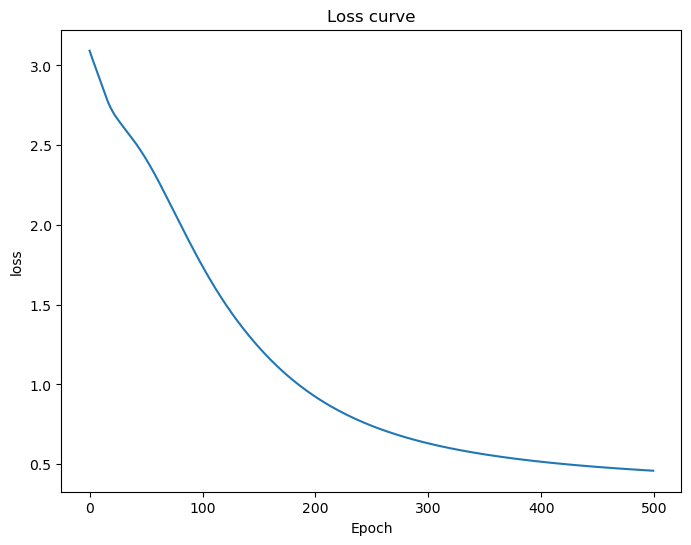

In [9]:
loss, cache = model.forward(X[:1], y[:1])
z = cache[-1]  # (1, T, V)

predicted_idx = np.argmax(z[0], axis=-1)

predicted_text = "".join(chars[i] for i in predicted_idx)
target_text = "".join(chars[i] for i in y[0])

print("Target:    ", target_text)
print("Prediction:", predicted_text)

plt.figure(figsize=(8,6))
plt.plot(loss_history)
plt.title("Loss curve")
plt.xlabel('Epoch')
plt.ylabel('loss')
plt.show()

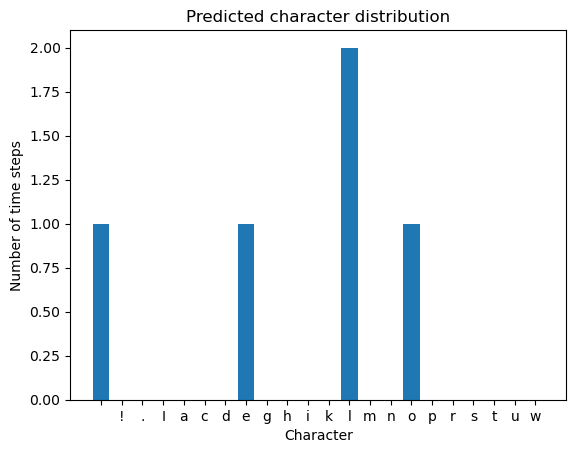

In [10]:
plt.hist(predicted_idx, bins=np.arange(V + 1) - 0.5, rwidth=0.8)
plt.xticks(range(V), chars)
plt.xlabel("Character")
plt.ylabel("Number of time steps")
plt.title("Predicted character distribution")
plt.show()

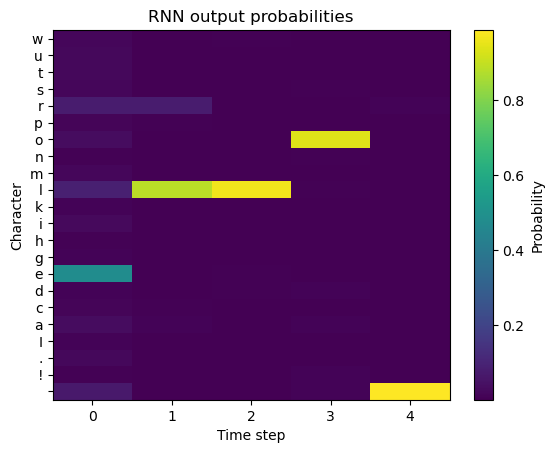

In [11]:
exp_z = np.exp(z[0] - np.max(z[0], axis=-1, keepdims=True))
probs = exp_z / np.sum(exp_z, axis=-1, keepdims=True)

plt.imshow(probs.T, aspect="auto", origin="lower", cmap="viridis")
plt.xticks(range(T))
plt.yticks(range(V), chars)
plt.xlabel("Time step")
plt.ylabel("Character")
plt.title("RNN output probabilities")
plt.colorbar(label="Probability")
plt.show()

In [12]:
import numpy as np

def generate_text(model, seed_text, char_to_idx, chars, T, num_chars=100):
    text = seed_text
    V = len(chars)

    for _ in range(num_chars):
        # Take the last T characters
        context = text[-T:]

        # Convert characters to integer indices
        context_idx = np.array([
            char_to_idx[c] for c in context
        ])

        # One-hot encode: (1, T, V)
        X_seed = np.eye(V)[context_idx][None, :, :]

        # Predict next character at each time step
        _, cache = model.forward(
            X_seed,
            np.zeros((1, T), dtype=int)
        )
        z = cache[-1]  # (1, T, V)

        # Choose prediction for the final time step
        next_idx = np.argmax(z[0, -1, :])
        next_char = chars[next_idx]

        # Append the predicted character
        text += next_char

    return text

In [13]:
print(generate_text(
    model=model,
    seed_text="hello",
    char_to_idx=char_to_idx,
    chars=chars,
    T=T,
    num_chars=100
))

hello world! deep learning recurrent neural networks. hello world! deep learning recurrent neural network
